# Day 21 — Class imbalance and appropriate evaluation metrics

Run each cell with **Shift + Enter**, from the top. We use `student_data_150.csv` (8 real students and 142 **synthetic** ones) and synthetic data generated in the notebook.

## 1. Understanding class imbalance and its impact

In [ ]:
# Get the student dataset: Colab starts with an empty folder. If the download fails, upload student_data_150.csv
# with the Files panel (the folder icon on the left) and run this cell again
import os
import urllib.request

URL = "https://raw.githubusercontent.com/neerajb1/learnforge-notebooks/main/ai-ml-120/day-021/data/student_data_150.csv"
if not os.path.exists("student_data_150.csv"):
    urllib.request.urlretrieve(URL, "student_data_150.csv")

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# Our students: how balanced are passing and failing? The 23 test students are set aside first, as every day
students = pd.read_csv("student_data_150.csv")
features = ["StudyHours", "Attendance", "PreviousScore"]
pool, test = train_test_split(students, test_size=0.15, random_state=42, stratify=students["Passed"])
X, y = pool[features], pool["Passed"].astype(int)          # 1 = pass, 0 = fail
for name, part in [("All 150", students), ("Training 127", pool)]:
    counts = part["Passed"].map({True: "pass", False: "fail"}).value_counts()
    print(f"{name:<13} pass {counts['pass']:>3} ({counts['pass'] / len(part):.1%})"
          f"  fail {counts['fail']:>3} ({counts['fail'] / len(part):.1%})"
          f"  ratio 1:{counts['pass'] / counts['fail']:.1f}")

All 150       pass 106 (70.7%)  fail  44 (29.3%)  ratio 1:2.4
Training 127  pass  90 (70.9%)  fail  37 (29.1%)  ratio 1:2.4


In [ ]:
# A highly imbalanced dataset: 1,000 synthetic card transactions, exactly 10 of them fraud (1%).
# Seeded, and not real: fraud here tends to be larger and at night, with plenty of overlap
rng = np.random.default_rng(21)
n, n_fraud = 1000, 10
is_fraud = np.zeros(n, dtype=int)
is_fraud[rng.choice(n, n_fraud, replace=False)] = 1
amount = np.where(is_fraud == 1, rng.lognormal(np.log(6000), 0.9, n), rng.lognormal(np.log(1500), 0.9, n)).round()
hour = np.where(is_fraud == 1, rng.choice([0, 1, 2, 3, 22, 23, 14, 19], n), rng.integers(7, 23, n))
transactions = pd.DataFrame({"TransactionID": np.arange(1, n + 1), "Amount": amount, "Hour": hour, "IsFraud": is_fraud})
print(transactions.head().to_string(index=False))
counts = transactions["IsFraud"].value_counts()
print(f"Legitimate (0): {counts[0]} ({counts[0] / n:.0%}) | fraud (1): {counts[1]} ({counts[1] / n:.0%})")
print(f"Imbalance ratio 1:{counts[0] // counts[1]}")

 TransactionID  Amount  Hour  IsFraud
             1   671.0    21        0
             2   791.0    12        0
             3  1177.0    19        0
             4  2615.0    16        0
             5   984.0    13        0
Legitimate (0): 990 (99%) | fraud (1): 10 (1%)
Imbalance ratio 1:99


In [ ]:
from sklearn.dummy import DummyClassifier

# The accuracy trap, in one line each: a "model" that always predicts the majority class
always_legit = DummyClassifier(strategy="most_frequent").fit(transactions[["Amount", "Hour"]], transactions["IsFraud"])
pred = always_legit.predict(transactions[["Amount", "Hour"]])
print(f"Transactions: accuracy {(pred == transactions['IsFraud']).mean():.3f},"
      f" frauds caught {((pred == 1) & (transactions['IsFraud'] == 1)).sum()} of 10")
always_pass = DummyClassifier(strategy="most_frequent").fit(X, y)
pred = always_pass.predict(X)
print(f"Students:     accuracy {(pred == y).mean():.3f}, failing students caught {((pred == 0) & (y == 0)).sum()} of {(y == 0).sum()}")

Transactions: accuracy 0.990, frauds caught 0 of 10
Students:     accuracy 0.709, failing students caught 0 of 37


In [ ]:
from sklearn.linear_model import LogisticRegression

# Impact on learning: the same two overlapping groups, only the minority's share changes.
# Logistic regression, trained on 75%, checked on the other 25% of each synthetic dataset
def overlapping_groups(minority_share, n=4000, seed=0):
    r = np.random.default_rng(seed)
    labels = (r.random(n) < minority_share).astype(int)
    points = r.normal(0, 1, (n, 2)) + labels[:, None] * 1.5      # the minority sits 1.5 units away: overlap
    return points, labels

print("minority  accuracy  minority recall  minority predicted / actual")
for share in [0.5, 0.2, 0.05, 0.01]:
    P, L = overlapping_groups(share)
    P_tr, P_va, L_tr, L_va = train_test_split(P, L, test_size=0.25, stratify=L, random_state=0)
    p = LogisticRegression().fit(P_tr, L_tr).predict(P_va)
    recall = ((p == 1) & (L_va == 1)).sum() / (L_va == 1).sum()
    print(f"{share:>8.0%}  {(p == L_va).mean():>8.3f}  {recall:>15.3f}  {(p == 1).sum():>9} / {(L_va == 1).sum()}")

minority  accuracy  minority recall  minority predicted / actual
     50%     0.860            0.854        500 / 508
     20%     0.898            0.702        186 / 208
      5%     0.966            0.453         29 / 53
      1%     0.990            0.000          0 / 10


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# On our students: every training student predicted by a model that didn't train on them (5-fold CV)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model = Pipeline([("scaler", StandardScaler()), ("classifier", LogisticRegression(max_iter=5000))])
pred = cross_val_predict(model, X, y, cv=cv)
cm = pd.crosstab(y.map({0: "Actual fail", 1: "Actual pass"}), pd.Series(pred, index=y.index).map({0: "Pred fail", 1: "Pred pass"}))
cm.index.name, cm.columns.name = None, None
print(cm.to_string())
print(f"Accuracy {(pred == y).mean():.3f}")
print(f"Passing students found: {((pred == 1) & (y == 1)).sum() / (y == 1).sum():.1%}")
print(f"Failing students found: {((pred == 0) & (y == 0)).sum() / (y == 0).sum():.1%}")

             Pred fail  Pred pass
Actual fail         22         15
Actual pass         11         79
Accuracy 0.795
Passing students found: 87.8%
Failing students found: 59.5%


## 2. Why accuracy becomes misleading

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix

# The accuracy trap at scale: 10,000 transactions, 9,900 legitimate (0) and 100 fraud (1); predict "legitimate" for all
actual = np.array([0] * 9900 + [1] * 100)
predicted = np.zeros_like(actual)
tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
print("               Pred legitimate  Pred fraud")
print(f"Actual legit   {tn:>15,}  {fp:>10,}")
print(f"Actual fraud   {fn:>15,}  {tp:>10,}")
print(f"Accuracy {accuracy_score(actual, predicted):.1%} | frauds detected {tp} of {tp + fn}")

               Pred legitimate  Pred fraud
Actual legit             9,900           0
Actual fraud               100           0
Accuracy 99.0% | frauds detected 0 of 100


In [ ]:
# Compare two models on the same 10,000 transactions (the mock's counts). FP = legitimate flagged as fraud
models_ab = {"A": {"TN": 9850, "TP": 20, "FN": 80}, "B": {"TN": 9700, "TP": 80, "FN": 20}}
for m in models_ab.values():
    m["FP"] = 9900 - m["TN"]
    m["accuracy"] = (m["TP"] + m["TN"]) / 10000
print("model  accuracy  fraud caught  fraud missed  false alarms")
for name, m in models_ab.items():
    print(f"{name:<5}  {m['accuracy']:>8.1%}  {m['TP']:>12}  {m['FN']:>12}  {m['FP']:>12}")
# Which is cheaper depends on the cost of each error. Cost = missed frauds x cost_miss + false alarms x cost_alarm
print("cost of a miss / cost of a false alarm -> cheaper model")
for ratio in [1, 2, 2.5, 3, 10, 50]:
    cost = {n: m["FN"] * ratio + m["FP"] for n, m in models_ab.items()}
    verdict = "tie" if cost["A"] == cost["B"] else min(cost, key=cost.get)
    print(f"{ratio:>5} x  A {cost['A']:>6,.0f}  B {cost['B']:>6,.0f}  -> {verdict}")

model  accuracy  fraud caught  fraud missed  false alarms
A         98.7%            20            80            50
B         97.8%            80            20           200
cost of a miss / cost of a false alarm -> cheaper model
    1 x  A    130  B    220  -> A
    2 x  A    210  B    240  -> A
  2.5 x  A    250  B    250  -> tie
    3 x  A    290  B    260  -> B
   10 x  A    850  B    400  -> B
   50 x  A  4,050  B  1,200  -> B


In [ ]:
# Majority-only accuracy as imbalance grows: a DummyClassifier fitted on each distribution
distributions = {"Balanced 50:50": (500, 500), "Moderate 90:10": (900, 100),
                 "High 99:1": (990, 10), "Extreme 999:1": (999, 1)}
print("distribution     accuracy  minority found")
for name, (majority, minority) in distributions.items():
    labels = np.array([0] * majority + [1] * minority)
    dummy = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(labels), 1)), labels)
    pred = dummy.predict(np.zeros((len(labels), 1)))
    print(f"{name:<15} {accuracy_score(labels, pred):>9.1%}  {((pred == 1) & (labels == 1)).sum():>6} of {minority}")

distribution     accuracy  minority found
Balanced 50:50      50.0%       0 of 500
Moderate 90:10      90.0%       0 of 100
High 99:1           99.0%       0 of 10
Extreme 999:1       99.9%       0 of 1


In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Real models on Section 1's 1,000 transactions (10 frauds), 5-fold stratified CV: 2 frauds per validation fold
Xt, yt = transactions[["Amount", "Hour"]], transactions["IsFraud"]
cv_t = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
candidates = {
    "Logistic regression": Pipeline([("scaler", StandardScaler()), ("classifier", LogisticRegression())]),
    "Decision tree (depth 3)": DecisionTreeClassifier(max_depth=3, random_state=42),
    "Logistic, balanced": Pipeline([("scaler", StandardScaler()),
                                    ("classifier", LogisticRegression(class_weight="balanced"))]),
}
print("model                    accuracy  fraud caught  false alarms")
for name, m in candidates.items():
    p = cross_val_predict(m, Xt, yt, cv=cv_t)
    print(f"{name:<24} {accuracy_score(yt, p):>8.3f}  {((p == 1) & (yt == 1)).sum():>6} of 10  {((p == 1) & (yt == 0)).sum():>12}")

model                    accuracy  fraud caught  false alarms
Logistic regression         0.989       1 of 10             2
Decision tree (depth 3)     0.993       4 of 10             1


Logistic, balanced          0.883       9 of 10           116


In [ ]:
# Our students, with "fail" as the positive class (the one we want to find). Cross-validated predictions
student_models = {
    "Always predict pass": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": model,
    "Logistic, balanced": Pipeline([("scaler", StandardScaler()),
                                    ("classifier", LogisticRegression(class_weight="balanced", max_iter=5000))]),
}
fail = (y == 0)
print("model                 accuracy   TP   FN   FP   TN")
for name, m in student_models.items():
    p_fail = cross_val_predict(m, X, y, cv=cv) == 0
    tp, fn = (p_fail & fail).sum(), (~p_fail & fail).sum()
    fp, tn = (p_fail & ~fail).sum(), (~p_fail & ~fail).sum()
    print(f"{name:<21} {(tp + tn) / len(y):>8.3f} {tp:>4} {fn:>4} {fp:>4} {tn:>4}")

model                 accuracy   TP   FN   FP   TN


Always predict pass      0.709    0   37    0   90


Logistic regression      0.795   22   15   11   79


Logistic, balanced       0.780   29    8   20   70


## 3. Precision, recall and F1-score

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

# The example: 10,000 transactions, 100 fraud. The model flags 280: 80 frauds (TP) and 200 legitimate (FP), missing 20 (FN)
y_true = np.array([1] * 100 + [0] * 9900)
y_pred = np.array([1] * 80 + [0] * 20 + [1] * 200 + [0] * 9700)
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
print(f"TP {tp}  FP {fp}  FN {fn}  TN {tn:,}")
print(f"Precision = TP / (TP + FP) = {tp} / {tp + fp} = {precision_score(y_true, y_pred):.4f}")
print(f"Recall    = TP / (TP + FN) = {tp} / {tp + fn} = {recall_score(y_true, y_pred):.4f}")
print(f"F1        = 2PR / (P + R)  = {f1_score(y_true, y_pred):.4f}")
print(f"Accuracy  = {accuracy_score(y_true, y_pred):.4f}")

TP 80  FP 200  FN 20  TN 9,700
Precision = TP / (TP + FP) = 80 / 280 = 0.2857
Recall    = TP / (TP + FN) = 80 / 100 = 0.8000
F1        = 2PR / (P + R)  = 0.4211
Accuracy  = 0.9780


In [ ]:
# Why the harmonic mean? It stays low when either precision or recall is low
print("precision  recall  arithmetic mean  F1 (harmonic)")
for p, r in [(0.9, 0.1), (0.5, 0.5), (0.2857, 0.8), (0.99, 0.01), (1.0, 0.0)]:
    f1 = 0 if p + r == 0 else 2 * p * r / (p + r)
    print(f"{p:>9.4f}  {r:>6.2f}  {(p + r) / 2:>15.3f}  {f1:>13.3f}")

precision  recall  arithmetic mean  F1 (harmonic)
   0.9000    0.10            0.500          0.180
   0.5000    0.50            0.500          0.500
   0.2857    0.80            0.543          0.421
   0.9900    0.01            0.500          0.020
   1.0000    0.00            0.500          0.000


In [ ]:
# A metric calculator: change TP, FP and FN (100 frauds in all) and see which metric moves
def metrics_from_counts(tp, fp, fn):
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return precision, recall, f1

print("  TP    FP  FN  precision  recall     F1")
for tp, fp, fn in [(80, 200, 20), (80, 50, 20), (80, 800, 20), (50, 200, 50), (95, 200, 5), (20, 5, 80)]:
    p, r, f = metrics_from_counts(tp, fp, fn)
    print(f"{tp:>4}  {fp:>4}  {fn:>2}  {p:>9.1%}  {r:>6.1%}  {f:>5.1%}")

  TP    FP  FN  precision  recall     F1
  80   200  20      28.6%   80.0%  42.1%
  80    50  20      61.5%   80.0%  69.6%
  80   800  20       9.1%   80.0%  16.3%
  50   200  50      20.0%   50.0%  28.6%
  95   200   5      32.2%   95.0%  48.1%
  20     5  80      80.0%   20.0%  32.0%


In [ ]:
from sklearn.metrics import fbeta_score

# F-beta: beta > 1 weights recall more, beta < 1 weights precision more. Two models, three scores
model_a = (y_true, y_pred)                                                   # TP 80, FP 200, FN 20: high recall
cautious = np.array([1] * 20 + [0] * 80 + [1] * 5 + [0] * 9895)               # TP 20, FP 5, FN 80: high precision
print("model            precision  recall   F0.5    F1     F2")
for name, pred in [("High recall", y_pred), ("High precision", cautious)]:
    print(f"{name:<15} {precision_score(y_true, pred):>10.3f} {recall_score(y_true, pred):>7.3f}"
          + "".join(f" {fbeta_score(y_true, pred, beta=b):>6.3f}" for b in [0.5, 1, 2]))

model            precision  recall   F0.5    F1     F2
High recall          0.286   0.800  0.328  0.421  0.588
High precision       0.800   0.200  0.500  0.320  0.235


In [ ]:
# The threshold on our students: out-of-fold probabilities of FAILING, then a range of cut-offs.
# Positive class = fail, so precision, recall and F scores are about finding failing students
p_fail = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 0]       # column 0 = class 0 = fail
actual_fail = (y == 0).astype(int)
print("threshold  flagged  precision  recall     F1     F2")
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    flag = (p_fail >= t).astype(int)
    print(f"{t:>9}  {flag.sum():>7}  {precision_score(actual_fail, flag, zero_division=0):>9.3f}"
          f"  {recall_score(actual_fail, flag):>6.3f}  {f1_score(actual_fail, flag):>5.3f}"
          f"  {fbeta_score(actual_fail, flag, beta=2):>5.3f}")

threshold  flagged  precision  recall     F1     F2
      0.2       63      0.524   0.892  0.660  0.782
      0.3       49      0.592   0.784  0.674  0.736


      0.4       37      0.595   0.595  0.595  0.595
      0.5       33      0.667   0.595  0.629  0.608
      0.6       24      0.708   0.459  0.557  0.494
      0.7       13      0.923   0.324  0.480  0.373


In [ ]:
from sklearn.metrics import classification_report

# classification_report: per class, then the averages. The weighted average is dominated by the 9,900 legitimate
print(classification_report(y_true, y_pred, target_names=["Legitimate", "Fraud"], digits=3))
for avg in ["binary", "macro", "micro", "weighted"]:
    print(f"F1, average={avg!r:<10} {f1_score(y_true, y_pred, average=avg):.3f}")

              precision    recall  f1-score   support

  Legitimate      0.998     0.980     0.989      9900
       Fraud      0.286     0.800     0.421       100

    accuracy                          0.978     10000
   macro avg      0.642     0.890     0.705     10000
weighted avg      0.991     0.978     0.983     10000

F1, average='binary'   0.421
F1, average='macro'    0.705
F1, average='micro'    0.978
F1, average='weighted' 0.983


In [ ]:
# Score held-out predictions, not training predictions: a fully grown tree on our students
tree = DecisionTreeClassifier(random_state=42).fit(X, y)
train_f1 = f1_score(y, tree.predict(X), pos_label=0)
cv_f1 = f1_score(y, cross_val_predict(DecisionTreeClassifier(random_state=42), X, y, cv=cv), pos_label=0)
print(f"F1 for fail on the training predictions: {train_f1:.3f}")
print(f"F1 for fail, cross-validated:            {cv_f1:.3f}")

F1 for fail on the training predictions: 1.000
F1 for fail, cross-validated:            0.500


## 4. Confusion matrix, ROC-AUC and PR-AUC

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

# The confusion matrix: rows = actual, columns = predicted; labels=[0, 1] fixes the order (fraud = 1 = positive)
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
print(cm)
(tn, fp), (fn, tp) = cm
print(f"Accuracy {(tp + tn) / cm.sum():.1%} | precision {tp / (tp + fp):.2%} | recall {tp / (tp + fn):.1%}")
print(f"TPR (= recall) {tp / (tp + fn):.3f} | FPR = FP / (FP + TN) = {fp / (fp + tn):.4f}")
# ConfusionMatrixDisplay(cm, display_labels=["Legitimate", "Fraud"]).plot() draws it as a coloured grid

[[9700  200]
 [  20   80]]


Accuracy 97.8% | precision 28.57% | recall 80.0%
TPR (= recall) 0.800 | FPR = FP / (FP + TN) = 0.0202


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

# ROC on our students: out-of-fold probabilities of failing (p_fail, Section 3), fail = positive
fpr, tpr, thr = roc_curve(actual_fail, p_fail)
print(f"ROC-AUC: {roc_auc_score(actual_fail, p_fail):.3f}")
# What ROC-AUC means: pick one failing and one passing student at random; how often does the failing one score higher?
fails, passes = p_fail[actual_fail == 1], p_fail[actual_fail == 0]
pairs = (fails[:, None] > passes[None, :]).mean() + 0.5 * (fails[:, None] == passes[None, :]).mean()
print(f"Share of fail-pass pairs ranked correctly: {pairs:.3f} (of {len(fails) * len(passes):,} pairs)")
print("threshold   FPR    TPR")
for t in [0.7, 0.5, 0.3, 0.2, 0.1]:
    i = np.where(thr >= t)[0][-1]                   # the last curve point at or above this threshold
    print(f"{t:>9}  {fpr[i]:.3f}  {tpr[i]:.3f}")

ROC-AUC: 0.849


Share of fail-pass pairs ranked correctly: 0.849 (of 3,330 pairs)
threshold   FPR    TPR
      0.7  0.011  0.081
      0.5  0.122  0.595
      0.3  0.211  0.784
      0.2  0.311  0.892
      0.1  0.433  0.946


In [ ]:
# ROC-AUC needs scores, not labels: from hard 0/1 predictions the "curve" has one corner
hard = (p_fail >= 0.5).astype(int)
print(f"ROC-AUC from probabilities: {roc_auc_score(actual_fail, p_fail):.3f}")
print(f"ROC-AUC from 0/1 labels:    {roc_auc_score(actual_fail, hard):.3f}")

ROC-AUC from probabilities: 0.849
ROC-AUC from 0/1 labels:    0.736


In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score, auc

# The precision-recall curve on our students. Its random baseline is the share of failing students
precision, recall, _ = precision_recall_curve(actual_fail, p_fail)
print(f"Average precision (AP):     {average_precision_score(actual_fail, p_fail):.3f}")
print(f"Trapezoidal area under PR:  {auc(recall, precision):.3f}")
print(f"Baseline (prevalence):      {actual_fail.mean():.3f}")

Average precision (AP):     0.712
Trapezoidal area under PR:  0.707
Baseline (prevalence):      0.291


In [ ]:
# Same ranking, rarer positives: one scoring rule (positives score 1.5 higher on average) at four prevalences.
# 10,000 negatives each time; only the number of positives changes
r = np.random.default_rng(4)
negatives = r.normal(0, 1, 10000)
print("positives  prevalence  ROC-AUC    AP   precision at recall 0.8")
for n_pos in [10000, 1000, 100, 10]:
    scores = np.concatenate([negatives, r.normal(1.5, 1, n_pos)])
    labels = np.concatenate([np.zeros(10000), np.ones(n_pos)])
    prec, rec, _ = precision_recall_curve(labels, scores)
    at_80 = prec[rec >= 0.8].max()
    print(f"{n_pos:>9,}  {n_pos / len(labels):>10.2%}  {roc_auc_score(labels, scores):>7.3f}"
          f"  {average_precision_score(labels, scores):.3f}  {at_80:>23.3f}")

positives  prevalence  ROC-AUC    AP   precision at recall 0.8


   10,000      50.00%    0.854  0.855                    0.761
    1,000       9.09%    0.851  0.457                    0.235
      100       0.99%    0.859  0.120                    0.029
       10       0.10%    0.910  0.016                    0.005


In [ ]:
from sklearn.datasets import make_classification

# The mock's experiment, with 20,000 rows instead of 5,000 so the 20% test set holds enough positives
Xs, ys = make_classification(n_samples=20000, n_features=12, n_informative=6, n_redundant=2,
                             weights=[0.99, 0.01], random_state=42)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.2, stratify=ys, random_state=42)
syn = Pipeline([("scaler", StandardScaler()), ("classifier", LogisticRegression(max_iter=2000))]).fit(Xs_tr, ys_tr)
proba = syn.predict_proba(Xs_te)[:, 1]
print(f"Test rows {len(ys_te):,}, positives {ys_te.sum()} ({ys_te.mean():.1%})")
print(f"ROC-AUC {roc_auc_score(ys_te, proba):.3f} | AP {average_precision_score(ys_te, proba):.3f}")
for t in [0.5, 0.3, 0.1]:
    p = (proba >= t).astype(int)
    (tn_, fp_), (fn_, tp_) = confusion_matrix(ys_te, p, labels=[0, 1])
    print(f"threshold {t}: TP {tp_:>3} FN {fn_:>3} FP {fp_:>4} | precision {precision_score(ys_te, p, zero_division=0):.3f}"
          f" recall {recall_score(ys_te, p):.3f}")

Test rows 4,000, positives 61 (1.5%)
ROC-AUC 0.722 | AP 0.296
threshold 0.5: TP   9 FN  52 FP    1 | precision 0.900 recall 0.148
threshold 0.3: TP  14 FN  47 FP    6 | precision 0.700 recall 0.230
threshold 0.1: TP  20 FN  41 FP   55 | precision 0.267 recall 0.328


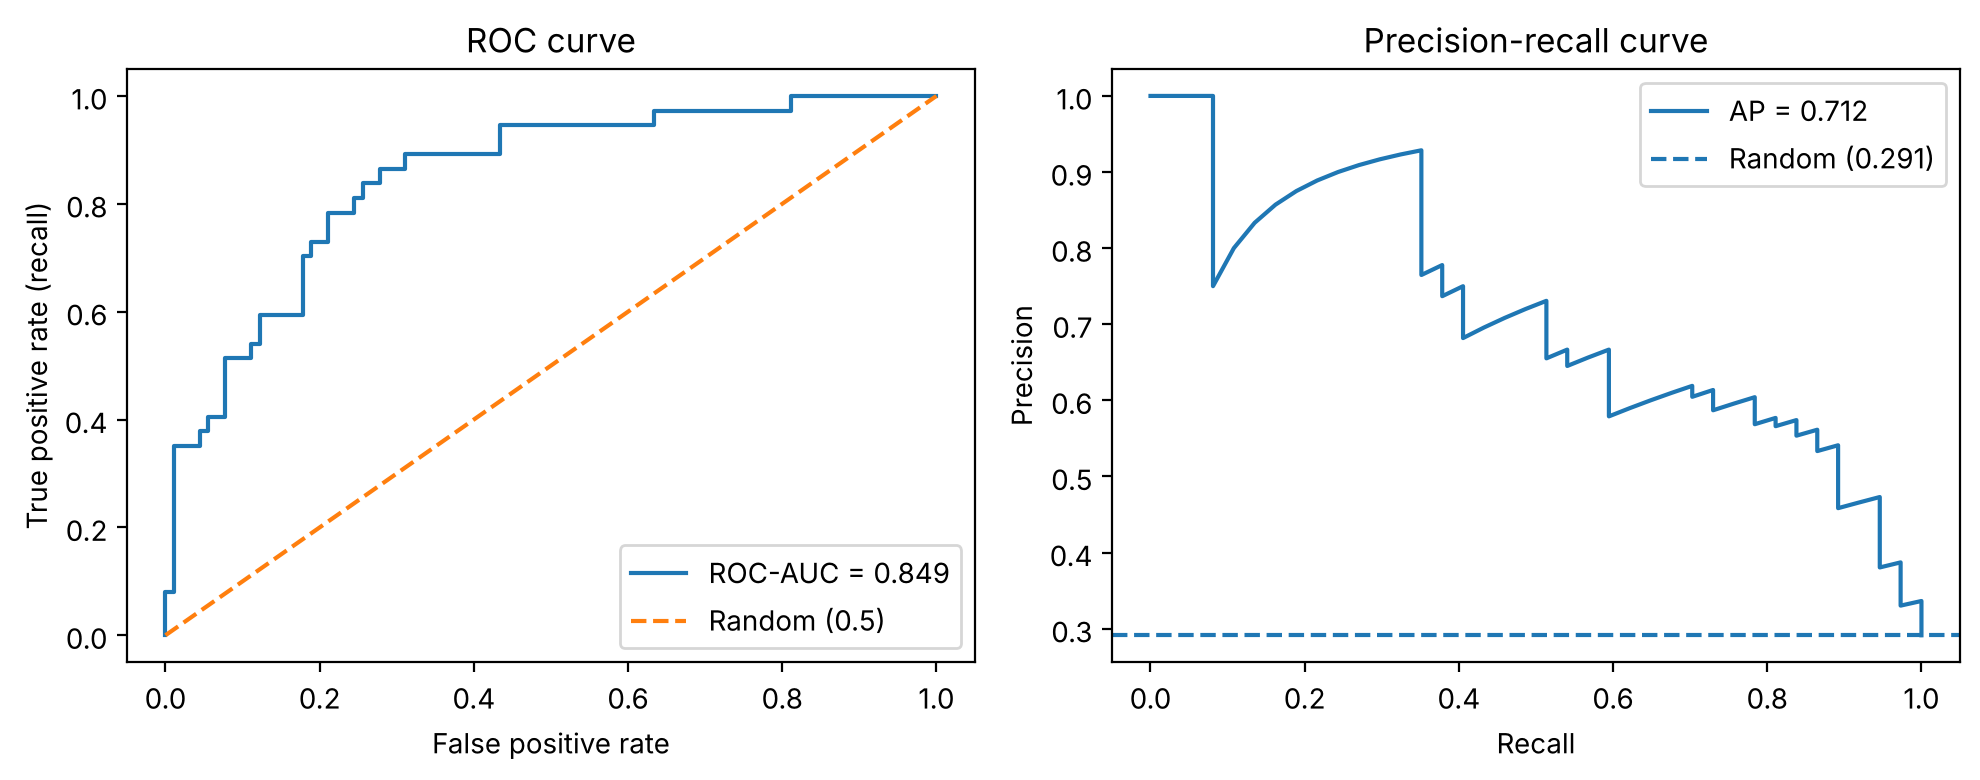

In [ ]:
import matplotlib.pyplot as plt

# Draw both curves for our students, with their random baselines
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))
left.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_score(actual_fail, p_fail):.3f}")
left.plot([0, 1], [0, 1], linestyle="--", label="Random (0.5)")
left.set(xlabel="False positive rate", ylabel="True positive rate (recall)", title="ROC curve")
right.plot(recall, precision, label=f"AP = {average_precision_score(actual_fail, p_fail):.3f}")
right.axhline(actual_fail.mean(), linestyle="--", label=f"Random ({actual_fail.mean():.3f})")
right.set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve")
for ax in (left, right):
    ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
import json

# The curve points the lesson page draws (at most 25 per curve, evenly spaced along it)
def thin(xs, ys, n=25):
    idx = np.unique(np.linspace(0, len(xs) - 1, n).round().astype(int))
    return [[round(float(xs[i]), 3), round(float(ys[i]), 3)] for i in idx]
print(json.dumps({"roc": thin(fpr, tpr), "pr": thin(recall[::-1], precision[::-1])}))

{"roc": [[0.0, 0.0], [0.0, 0.027], [0.011, 0.081], [0.011, 0.351], [0.044, 0.378], [0.056, 0.378], [0.078, 0.405], [0.078, 0.514], [0.111, 0.541], [0.122, 0.541], [0.178, 0.595], [0.178, 0.703], [0.189, 0.73], [0.211, 0.73], [0.211, 0.784], [0.244, 0.811], [0.256, 0.811], [0.278, 0.838], [0.278, 0.865], [0.311, 0.892], [0.433, 0.892], [0.633, 0.946], [0.633, 0.973], [0.811, 1.0], [1.0, 1.0]], "pr": [[0.0, 1.0], [0.108, 0.8], [0.27, 0.909], [0.351, 0.812], [0.405, 0.714], [0.514, 0.731], [0.568, 0.656], [0.595, 0.595], [0.703, 0.619], [0.784, 0.604], [0.811, 0.566], [0.865, 0.552], [0.892, 0.516], [0.892, 0.478], [0.946, 0.473], [0.946, 0.443], [0.946, 0.412], [0.946, 0.389], [0.973, 0.379], [0.973, 0.356], [0.973, 0.34], [1.0, 0.333], [1.0, 0.319], [1.0, 0.303], [1.0, 0.291]]}


## 5. Resampling techniques and SMOTE

In [ ]:
# imbalanced-learn isn't part of Colab or the notebook's earlier libraries: install it if it's missing
import importlib.util, subprocess, sys
if importlib.util.find_spec("imblearn") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])
from collections import Counter
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE

# The mock's dataset: 10,000 rows, about 1% positive. Split FIRST; resample only the training part
Xr, yr = make_classification(n_samples=10000, n_features=10, n_informative=5, n_redundant=2,
                             weights=[0.99, 0.01], random_state=42)
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, stratify=yr, random_state=42)
counts = lambda labels: {int(k): v for k, v in sorted(Counter(labels).items())}
print("Training, original:", counts(yr_tr), "| test (never resampled):", counts(yr_te))
for name, sampler in [("Random undersampling", RandomUnderSampler(random_state=42)),
                      ("Random oversampling", RandomOverSampler(random_state=42)),
                      ("SMOTE", SMOTE(random_state=42, k_neighbors=5))]:
    Xs_, ys_ = sampler.fit_resample(Xr_tr, yr_tr)
    print(f"{name:<21} {counts(ys_)}  rows {len(ys_):,}  distinct rows {len(np.unique(Xs_, axis=0)):,}")

Training, original: {0: 7882, 1: 118} | test (never resampled): {0: 1971, 1: 29}
Random undersampling  {0: 118, 1: 118}  rows 236  distinct rows 236
Random oversampling   {0: 7882, 1: 7882}  rows 15,764  distinct rows 8,000
SMOTE                 {0: 7882, 1: 7882}  rows 15,764  distinct rows 15,764


In [ ]:
# SMOTE's interpolation by hand: x_new = x_i + lambda * (x_neighbour - x_i), lambda between 0 and 1
x1, x2 = np.array([2, 4]), np.array([6, 8])
for lam in [0, 0.25, 0.5, 1]:
    print(f"lambda {lam:<4} -> {x1 + lam * (x2 - x1)}")
# Check on real SMOTE output: every synthetic point lies on a segment between two training minority points
minority = Xr_tr[yr_tr == 1]
X_sm, y_sm = SMOTE(random_state=42).fit_resample(Xr_tr, yr_tr)
synthetic = X_sm[len(yr_tr):]                          # imbalanced-learn appends the new rows at the end
def on_a_segment(p):
    for a in minority:
        d = minority - a                                # directions to every other minority point
        lam = (d @ (p - a)) / np.maximum((d * d).sum(1), 1e-12)
        if np.any((lam >= 0) & (lam <= 1) & np.all(np.abs(a + lam[:, None] * d - p) < 1e-9, axis=1)):
            return True
    return False
print(f"Synthetic points: {len(synthetic)}; first 200 checked, on a segment: {sum(on_a_segment(p) for p in synthetic[:200])}")

lambda 0    -> [2 4]
lambda 0.25 -> [3. 5.]
lambda 0.5  -> [4. 6.]
lambda 1    -> [6 8]


Synthetic points: 7764; first 200 checked, on a segment: 200


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

# Class weights, "balanced": w_j = n / (K x n_j). For our 127 training students, fail = 0 and pass = 1
n, K = len(y), 2
for label, name in [(0, "fail"), (1, "pass")]:
    n_j = (y == label).sum()
    print(f"{name}: {n} / ({K} x {n_j}) = {n / (K * n_j):.3f}")
print("compute_class_weight:", compute_class_weight("balanced", classes=np.array([0, 1]), y=y).round(3))
w = compute_class_weight("balanced", classes=np.array([0, 1]), y=yr_tr)
print(f"Synthetic training set: weight {w[1]:.2f} for each positive, {w[0]:.3f} for each negative")

fail: 127 / (2 x 37) = 1.716
pass: 127 / (2 x 90) = 0.706
compute_class_weight: [1.716 0.706]
Synthetic training set: weight 33.90 for each positive, 0.507 for each negative


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# The leakage trap: resampling BEFORE splitting puts copies (or interpolations) of the same frauds on both sides
def test_f1(Xa, ya, Xb, yb):
    rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(Xa, ya)
    p = rf.predict(Xb)
    return f1_score(yb, p), recall_score(yb, p)

print("workflow                                 test F1  test recall")
for name, sampler in [("Oversample", RandomOverSampler(random_state=42)), ("SMOTE", SMOTE(random_state=42))]:
    Xw, yw = sampler.fit_resample(Xr, yr)                                    # wrong: resample everything
    a, b, c, d = train_test_split(Xw, yw, test_size=0.2, stratify=yw, random_state=42)
    wrong = test_f1(a, c, b, d)
    Xok, yok = sampler.fit_resample(Xr_tr, yr_tr)                            # right: training part only
    right = test_f1(Xok, yok, Xr_te, yr_te)
    print(f"{name + ' before the split (leaks)':<38} {wrong[0]:>8.3f}  {wrong[1]:>11.3f}")
    print(f"{name + ' training data only':<38} {right[0]:>8.3f}  {right[1]:>11.3f}")

workflow                                 test F1  test recall


Oversample before the split (leaks)       0.999        1.000
Oversample training data only             0.270        0.172


SMOTE before the split (leaks)            0.992        0.996
SMOTE training data only                  0.333        0.345


In [ ]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer

# Compare five approaches on the same 5 folds of the training data. The imblearn Pipeline resamples
# only each fold's training part, after scaling it; validation rows keep the original 1%
experiments = {"No resampling": None, "Undersampling": RandomUnderSampler(random_state=42),
               "Oversampling": RandomOverSampler(random_state=42), "SMOTE": SMOTE(random_state=42),
               "Class weighting": "balanced"}
cv_r = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"precision": make_scorer(precision_score, zero_division=0), "recall": "recall", "f1": "f1",
           "average_precision": "average_precision"}          # zero_division=0: a fold with no positive predictions
print("method           precision  recall     F1     AP")
for name, sampler in experiments.items():
    steps = [("scaler", StandardScaler())]
    if sampler not in (None, "balanced"):
        steps.append(("sampler", sampler))
    steps.append(("classifier", LogisticRegression(max_iter=2000, class_weight="balanced" if sampler == "balanced" else None)))
    s = cross_validate(ImbPipeline(steps), Xr_tr, yr_tr, cv=cv_r, scoring=scoring)
    print(f"{name:<16} {s['test_precision'].mean():>9.3f}  {s['test_recall'].mean():>6.3f}"
          f"  {s['test_f1'].mean():>5.3f}  {s['test_average_precision'].mean():>5.3f}")

method           precision  recall     F1     AP
No resampling        0.200   0.009  0.017  0.139
Undersampling        0.026   0.637  0.050  0.060


Oversampling         0.028   0.620  0.054  0.068
SMOTE                0.029   0.621  0.055  0.084
Class weighting      0.028   0.620  0.054  0.069


In [ ]:
# The same comparison on our 127 training students, fail recoded as 1 so the standard scorers treat it as positive
y_fail = 1 - y
print("method           precision  recall     F1     AP")
for name, sampler in experiments.items():
    steps = [("scaler", StandardScaler())]
    if sampler not in (None, "balanced"):
        steps.append(("sampler", sampler))
    steps.append(("classifier", LogisticRegression(max_iter=5000, class_weight="balanced" if sampler == "balanced" else None)))
    s = cross_validate(ImbPipeline(steps), X, y_fail, cv=cv, scoring=scoring)
    print(f"{name:<16} {s['test_precision'].mean():>9.3f}  {s['test_recall'].mean():>6.3f}"
          f"  {s['test_f1'].mean():>5.3f}  {s['test_average_precision'].mean():>5.3f}")

method           precision  recall     F1     AP


No resampling        0.687   0.593  0.619  0.722
Undersampling        0.636   0.814  0.706  0.751


Oversampling         0.584   0.761  0.654  0.716


SMOTE                0.645   0.814  0.712  0.724
Class weighting      0.620   0.786  0.679  0.722


In [ ]:
from imblearn.over_sampling import SMOTENC

# Mixed data: our students' Class (a category) with three numbers. Plain SMOTE on one-hot columns invents
# fractional "classes"; SMOTENC keeps each synthetic student in a real class
Xc = pool[["StudyHours", "Attendance", "PreviousScore", "Class"]].reset_index(drop=True)
onehot = pd.get_dummies(Xc, columns=["Class"], dtype=float)
plain, _ = SMOTE(random_state=42).fit_resample(onehot, y_fail.reset_index(drop=True))
class_cols = [c for c in plain.columns if c.startswith("Class_")]
new_rows = plain.iloc[len(Xc):][class_cols]
print(f"Plain SMOTE: {len(new_rows)} new students, {((new_rows > 0) & (new_rows < 1)).any(axis=1).sum()} with a fractional class")
nc, _ = SMOTENC(categorical_features=[3], random_state=42).fit_resample(Xc, y_fail.reset_index(drop=True))
print(f"SMOTENC:     {len(nc) - len(Xc)} new students, classes used: {sorted(nc.iloc[len(Xc):]['Class'].unique())}")

Plain SMOTE: 53 new students, 34 with a fractional class
SMOTENC:     53 new students, classes used: ['A', 'B', 'C']


## 6. Best practices and mini project

In [ ]:
# Day 21's final check, once: the 23 test students set aside in Section 1. The rule, fixed before looking:
# the approach with the best CV F1 for failing students in Section 5 (SMOTE), its threshold from out-of-fold probabilities
smote_students = ImbPipeline([("scaler", StandardScaler()), ("sampler", SMOTE(random_state=42)),
                              ("classifier", LogisticRegression(max_iter=5000))])
oof = cross_val_predict(smote_students, X, y_fail, cv=cv, method="predict_proba")[:, 1]
grid_t = np.round(np.arange(0.2, 0.81, 0.05), 2)
t_best = max(grid_t, key=lambda t: f1_score(y_fail, (oof >= t).astype(int)))
print(f"Threshold with the best out-of-fold F1: {t_best} (F1 {f1_score(y_fail, (oof >= t_best).astype(int)):.3f})")
smote_students.fit(X, y_fail)
test_fail = 1 - test["Passed"].astype(int)
flag = (smote_students.predict_proba(test[features])[:, 1] >= t_best).astype(int)
(tn_, fp_), (fn_, tp_) = confusion_matrix(test_fail, flag, labels=[0, 1])
print(f"Test students: {len(test_fail)}, failing {test_fail.sum()} | caught {tp_}, missed {fn_}, false alarms {fp_}")
print(f"Precision {precision_score(test_fail, flag):.3f} | recall {recall_score(test_fail, flag):.3f}"
      f" | F1 {f1_score(test_fail, flag):.3f}")

Threshold with the best out-of-fold F1: 0.5 (F1 0.706)
Test students: 23, failing 7 | caught 5, missed 2, false alarms 1
Precision 0.833 | recall 0.714 | F1 0.769


In [ ]:
# The mini project: a synthetic fraud dataset (the mock's settings, seeded). Not real transactions
Xf, yf = make_classification(n_samples=10000, n_features=12, n_informative=6, n_redundant=2,
                             n_clusters_per_class=2, weights=[0.99, 0.01], flip_y=0.001, random_state=42)
fraud = pd.DataFrame(Xf, columns=[f"feature_{i}" for i in range(12)])
fraud["is_fraud"] = yf
counts_f = fraud["is_fraud"].value_counts()
print(f"Legitimate {counts_f[0]:,} ({counts_f[0] / len(fraud):.2%}) | fraud {counts_f[1]} ({counts_f[1] / len(fraud):.2%})")
print(f"Imbalance ratio about 1:{counts_f[0] / counts_f[1]:.0f}")

Legitimate 9,893 (98.93%) | fraud 107 (1.07%)
Imbalance ratio about 1:92


In [ ]:
# Step 2: three stratified sets. Training (70%) for fitting and resampling, validation (15%) for choosing
# the model and threshold, test (15%) once at the end. Count the frauds each one gets
Xf_all, yf_all = fraud.drop(columns="is_fraud"), fraud["is_fraud"]
Xf_tr, Xf_tmp, yf_tr, yf_tmp = train_test_split(Xf_all, yf_all, test_size=0.30, stratify=yf_all, random_state=42)
Xf_va, Xf_te, yf_va, yf_te = train_test_split(Xf_tmp, yf_tmp, test_size=0.50, stratify=yf_tmp, random_state=42)
for name, part in [("Training", yf_tr), ("Validation", yf_va), ("Test", yf_te)]:
    print(f"{name:<11} {len(part):>5,} rows, {part.sum():>3} frauds ({part.mean():.2%})")

Training    7,000 rows,  75 frauds (1.07%)
Validation  1,500 rows,  16 frauds (1.07%)
Test        1,500 rows,  16 frauds (1.07%)


In [ ]:
# Step 3: the majority-class baseline, on validation
base = DummyClassifier(strategy="most_frequent").fit(Xf_tr, yf_tr)
bp = base.predict(Xf_va)
print(f"Accuracy {accuracy_score(yf_va, bp):.3f} | precision {precision_score(yf_va, bp, zero_division=0):.3f}"
      f" | recall {recall_score(yf_va, bp):.3f} | F1 {f1_score(yf_va, bp):.3f}")
print(confusion_matrix(yf_va, bp, labels=[0, 1]))

Accuracy 0.989 | precision 0.000 | recall 0.000 | F1 0.000
[[1484    0]
 [  16    0]]


In [ ]:
# Step 4: five approaches, each fitted on training data only, scored on the untouched validation set.
# ROC-AUC and AP rank across thresholds; precision, recall and F1 are at the default 0.5
def lr_pipe(sampler=None, weight=None):
    steps = [("scaler", StandardScaler())] + ([("sampler", sampler)] if sampler else [])
    return ImbPipeline(steps + [("classifier", LogisticRegression(max_iter=2000, class_weight=weight))])

approaches = {"Normal": lr_pipe(), "Class weighting": lr_pipe(weight="balanced"),
              "Oversampling": lr_pipe(RandomOverSampler(random_state=42)),
              "SMOTE": lr_pipe(SMOTE(random_state=42, k_neighbors=5)),
              "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2,          # can model clusters
                                                      class_weight="balanced_subsample", random_state=42, n_jobs=-1)}
val_proba = {}
print("approach         ROC-AUC     AP  precision  recall     F1")
for name, m in approaches.items():
    val_proba[name] = m.fit(Xf_tr, yf_tr).predict_proba(Xf_va)[:, 1]
    p = (val_proba[name] >= 0.5).astype(int)
    print(f"{name:<16} {roc_auc_score(yf_va, val_proba[name]):>7.3f}  {average_precision_score(yf_va, val_proba[name]):.3f}"
          f"  {precision_score(yf_va, p, zero_division=0):>9.3f}  {recall_score(yf_va, p):>6.3f}  {f1_score(yf_va, p):.3f}")

approach         ROC-AUC     AP  precision  recall     F1


Normal             0.858  0.447      1.000   0.188  0.316
Class weighting    0.846  0.363      0.046   0.812  0.087


Oversampling       0.843  0.351      0.047   0.812  0.088
SMOTE              0.854  0.406      0.047   0.750  0.089


Random forest      0.842  0.599      1.000   0.125  0.222


In [ ]:
# Step 5: the best ranking on validation is not the end. Which approach has the best AP, and what can it reach?
best_ap = max(val_proba, key=lambda n: average_precision_score(yf_va, val_proba[n]))
pv = val_proba[best_ap]
print("Best validation AP:", best_ap)
print("threshold  flagged  caught  precision  recall     F1")
for t in [0.01, 0.05, 0.1, 0.2, 0.3, 0.5]:
    p = (pv >= t).astype(int)
    print(f"{t:>9}  {p.sum():>7}  {(p & yf_va.values).sum():>3} / {yf_va.sum()}  {precision_score(yf_va, p, zero_division=0):>9.3f}"
          f"  {recall_score(yf_va, p):>6.3f}  {f1_score(yf_va, p):.3f}")

Best validation AP: Random forest
threshold  flagged  caught  precision  recall     F1
     0.01      339   13 / 16      0.038   0.812  0.073
     0.05       59   12 / 16      0.203   0.750  0.320
      0.1       24   11 / 16      0.458   0.688  0.550
      0.2        7    6 / 16      0.857   0.375  0.522
      0.3        6    6 / 16      1.000   0.375  0.545
      0.5        2    2 / 16      1.000   0.125  0.222


In [ ]:
# Step 6: the business rule chooses the approach AND the threshold: recall of at least 85% on validation,
# then the highest precision. Every approach, thresholds 0.01 to 0.99
print("approach         meeting it  precision  threshold  recall")
options = []
for name, pv_ in val_proba.items():
    ok = []
    for t in np.linspace(0.01, 0.99, 99):
        p = (pv_ >= t).astype(int)
        if recall_score(yf_va, p) >= 0.85:
            ok.append((precision_score(yf_va, p, zero_division=0), round(t, 2), recall_score(yf_va, p)))
    if ok:
        best = max(ok)
        options.append((best[0], name, best[1], best[2]))
        print(f"{name:<16} {len(ok):>10}  {best[0]:>9.3f}  {best[1]:>9}  {best[2]:.3f}")
    else:
        print(f"{name:<16} {0:>10}  {'-':>9}  {'-':>9}  -")
best_precision, chosen_name, threshold_f, best_recall = max(options)
print(f"Chosen: {chosen_name} at threshold {threshold_f}")
print(f"One validation fraud is {1 / yf_va.sum():.1%} of recall: the rule rests on {yf_va.sum()} frauds")

approach         meeting it  precision  threshold  recall


Normal                    0          -          -  -


Class weighting          18      0.015       0.18  0.875


Oversampling             18      0.016       0.18  0.875


SMOTE                    14      0.016       0.14  0.875
Random forest             0          -          -  -
Chosen: SMOTE at threshold 0.14
One validation fraud is 6.2% of recall: the rule rests on 16 frauds


In [ ]:
# Step 7: the final test, once. The chosen approach (refitted on training data only) and the chosen threshold
test_p = approaches[chosen_name].predict_proba(Xf_te)[:, 1]
test_flag = (test_p >= threshold_f).astype(int)
print(classification_report(yf_te, test_flag, target_names=["Legitimate", "Fraud"], digits=3, zero_division=0))
print(confusion_matrix(yf_te, test_flag, labels=[0, 1]))
print(f"Test ROC-AUC {roc_auc_score(yf_te, test_p):.3f} | AP {average_precision_score(yf_te, test_p):.3f}"
      f" | frauds caught {(test_flag & yf_te.values).sum()} of {yf_te.sum()}")

              precision    recall  f1-score   support

  Legitimate      0.998     0.396     0.567      1484
       Fraud      0.016     0.938     0.032        16

    accuracy                          0.401      1500
   macro avg      0.507     0.667     0.299      1500
weighted avg      0.988     0.401     0.561      1500

[[587 897]
 [  1  15]]
Test ROC-AUC 0.832 | AP 0.216 | frauds caught 15 of 16
